<a href="https://colab.research.google.com/github/ShreyaBawankar77/Hack-O-Week/blob/main/Week13_14.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import BaggingRegressor
from sklearn.linear_model import Ridge, Lasso

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

In [ ]:
data = fetch_california_housing()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")

print("Dataset Shape:", X.shape)
print(X.head())

Dataset Shape: (20640, 8)
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  
0    -122.23  
1    -122.22  
2    -122.24  
3    -122.25  
4    -122.25  


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (16512, 8)
Testing data: (4128, 8)


In [ ]:
bagging = BaggingRegressor(
    estimator=DecisionTreeRegressor(random_state=42),
    n_estimators=100,
    random_state=42
)

bagging.fit(X_train, y_train)

bag_pred = bagging.predict(X_test)

print("Bagging")
print("R2:", r2_score(y_test, bag_pred))
print("MAE:", mean_absolute_error(y_test, bag_pred))
print("MSE:", mean_squared_error(y_test, bag_pred))

Bagging
R2: 0.8046988456668309
MAE: 0.32789687759205444
MSE: 0.25592438609899626


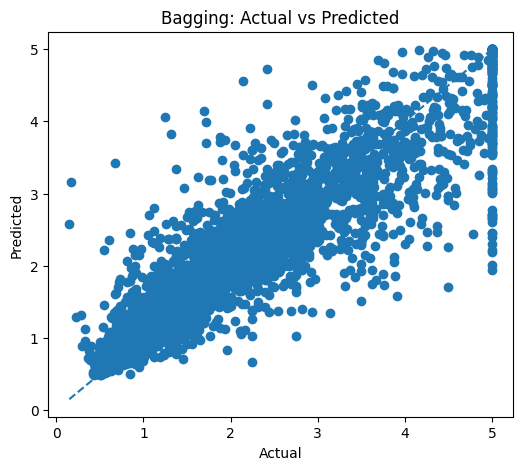

In [ ]:
plt.figure(figsize=(6,5))

plt.scatter(y_test, bag_pred)

plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Bagging: Actual vs Predicted")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.show()

In [ ]:
xgb = XGBRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

xgb.fit(X_train, y_train)

xgb_pred = xgb.predict(X_test)

print("XGBoost")
print("R2:", r2_score(y_test, xgb_pred))
print("MAE:", mean_absolute_error(y_test, xgb_pred))
print("MSE:", mean_squared_error(y_test, xgb_pred))

XGBoost
R2: 0.7428348370806668
MAE: 0.40419290868560936
MSE: 0.33699153838027796


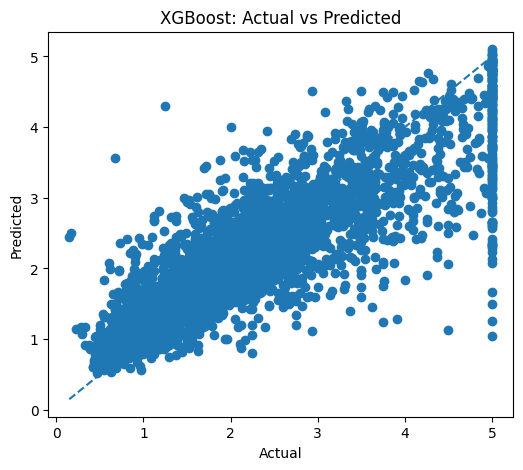

In [ ]:
plt.figure(figsize=(6,5))

plt.scatter(y_test, xgb_pred)

plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("XGBoost: Actual vs Predicted")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.show()

In [ ]:
lgb = LGBMRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    random_state=42,
    verbosity=-1
)

lgb.fit(X_train, y_train)

lgb_pred = lgb.predict(X_test)

print("LightGBM")
print("R2:", r2_score(y_test, lgb_pred))
print("MAE:", mean_absolute_error(y_test, lgb_pred))
print("MSE:", mean_squared_error(y_test, lgb_pred))

LightGBM
R2: 0.7427468028784112
MAE: 0.4041088915079177
MSE: 0.33710689918930586


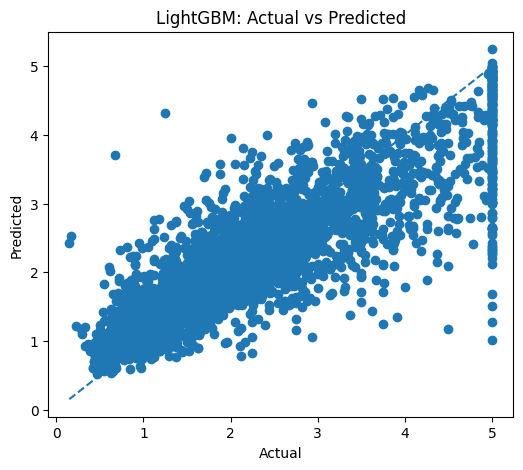

In [ ]:
plt.figure(figsize=(6,5))

plt.scatter(y_test, lgb_pred)

plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("LightGBM: Actual vs Predicted")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.show()

In [ ]:
depths = [1, 2, 3, 5, 10, 15, 20]

train_r2 = []
test_r2 = []

for depth in depths:

    model = DecisionTreeRegressor(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_r2.append(
        r2_score(y_train, model.predict(X_train))
    )

    test_r2.append(
        r2_score(y_test, model.predict(X_test))
    )

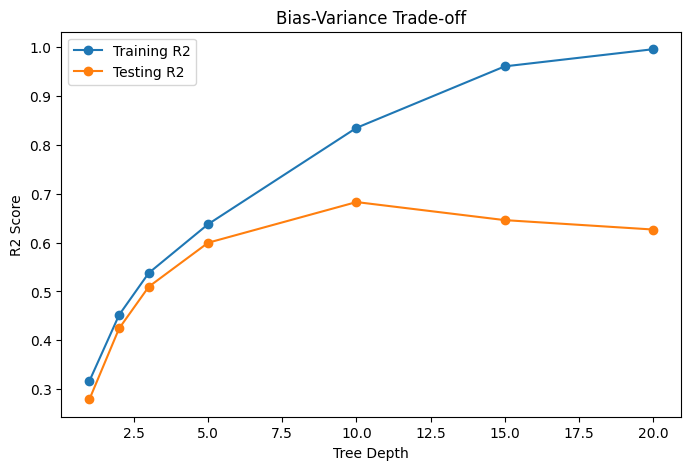

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(
    depths,
    train_r2,
    marker="o",
    label="Training R2"
)

plt.plot(
    depths,
    test_r2,
    marker="o",
    label="Testing R2"
)

plt.xlabel("Tree Depth")
plt.ylabel("R2 Score")
plt.title("Bias-Variance Trade-off")
plt.legend()

plt.show()

In [ ]:
lasso = Lasso(alpha=0.1)

lasso.fit(X_train, y_train)

lasso_pred = lasso.predict(X_test)

print("L1 - Lasso")
print("R2:", r2_score(y_test, lasso_pred))

L1 - Lasso
R2: 0.5318167610318159


In [ ]:
ridge = Ridge(alpha=1.0)

ridge.fit(X_train, y_train)

ridge_pred = ridge.predict(X_test)

print("L2 - Ridge")
print("R2:", r2_score(y_test, ridge_pred))

L2 - Ridge
R2: 0.5758549611440126


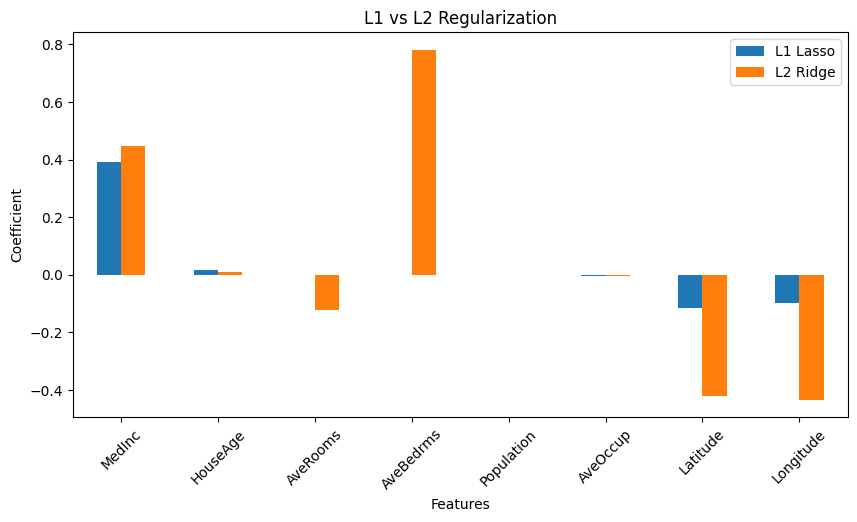

In [ ]:
coef = pd.DataFrame({
    "Feature": X.columns,
    "L1 Lasso": lasso.coef_,
    "L2 Ridge": ridge.coef_
})

coef.set_index("Feature").plot(
    kind="bar",
    figsize=(10,5)
)

plt.title("L1 vs L2 Regularization")
plt.xlabel("Features")
plt.ylabel("Coefficient")
plt.xticks(rotation=45)

plt.show()

In [ ]:
results = pd.DataFrame({
    "Model": [
        "Bagging",
        "XGBoost",
        "LightGBM",
        "L1 Lasso",
        "L2 Ridge"
    ],

    "R2": [
        r2_score(y_test, bag_pred),
        r2_score(y_test, xgb_pred),
        r2_score(y_test, lgb_pred),
        r2_score(y_test, lasso_pred),
        r2_score(y_test, ridge_pred)
    ]
})

print(results)

      Model        R2
0   Bagging  0.804699
1   XGBoost  0.742835
2  LightGBM  0.742747
3  L1 Lasso  0.531817
4  L2 Ridge  0.575855


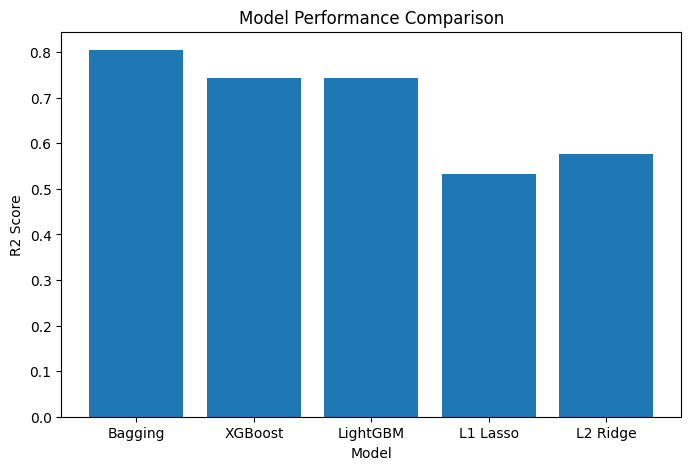

In [ ]:
plt.figure(figsize=(8,5))

plt.bar(
    results["Model"],
    results["R2"]
)

plt.xlabel("Model")
plt.ylabel("R2 Score")
plt.title("Model Performance Comparison")

plt.show()